# 105_03 — Convergencia de las cadenas MCMC · Beijing (12 estaciones, promedio) horario · PM2.5 (log) · **barrido en $M$**

Paso **3a** del ciclo. Este notebook **sólo diagnostica las cadenas**: no
predice, no evalúa y no toca el bloque de prueba. Si algo aquí falla, los
números de `105_04` no significan nada, y por eso son notebooks separados.

Los cálculos viven en `fit/convergencia_barrido.py` y las figuras en
`graphics/viz_convergencia.py`; este notebook los orquesta.

Covariables cruzadas con un solo rezago ($p=M$): el diseño cambia con $M$, así que MATLAB entrena **cada** $M$ y `hyperparameters.json["trazas_en"]` apunta al propio punto. Datos reales: no hay generador contra el cual contrastar la selección (§6).

| Estadístico | Referencia | Lectura |
|---|---|---|
| ESS | Geyer (1992) | $\gtrsim 400$ ideal, $>100$ aceptable |
| Geweke $z$ | test $z$ entre segmentos | $\lvert z\rvert < 2$ ⇒ no se rechaza |
| $\hat R$ | Gelman-Rubin | $< 1.1$ ⇒ convergencia |

## 1. Imports, `[CONFIG]` y artefactos

In [1]:
import sys

import matplotlib.pyplot as plt

from model_psbp_fd.fit.convergencia_barrido import (
    cargar_artefactos, cargar_trazas, diagnosticar_punto, imprimir_convergencia,
    ocupacion_mezcla, diagnostico_gating, pip_punto,
    verificar_muestreador_predictor, diagnostico_paso_gamma,
    tabla_barrido, ocupacion_barrido, pip_barrido, veredicto_barrido,
)
from model_psbp_fd.graphics import (
    plot_global_components, plot_active_clusters,
    plot_convergence_bj, plot_convergence_pj,
    plot_ocupacion_mezcla, plot_gating, plot_diagnostico_vs_M,
    plot_ocupacion_vs_M, plot_pip_vs_M,
)
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [2]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Identidad de la corrida: mismos valores que 105_01 §1.1. El ID es
# real_<serie>_v<NN>_m<NN>; las funciones de fit/ lo arman con (BASE_LIB, ESCENARIO_ID, None).
BASENAME, SERIE_ID, VENTANA_ID = "real", "beijing_105", 1   # ventana 1: 2013-03-01 .. 2017-02-28, 70/30 (105_01 §1.1)
M_FPCA_LIST = (10,)
DOMINIO      = "reales"
BASE_LIB     = f"{BASENAME}_{SERIE_ID}"
ESCENARIO_ID = f"v{VENTANA_ID:02d}"
REPLICA_ID   = None

# Propias de la convergencia.
SALTAR_M_SIN_TRAZAS = True    # mirar el barrido mientras MATLAB va terminando
BURN_EVAL           = None    # iteraciones descartadas; None = el burn del .mat
SD_PIP_MAX          = 0.15    # dispersión entre cadenas que se avisa
CORR_MIN_CONTRATO   = 0.999   # corr(inEout, predict) mínima, §7

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASE_LIB, ESCENARIO_ID, REPLICA_ID)
# Salidas que CRUZAN los M: directorio hermano de los de cada punto.
PATH_BARRIDO    = ruta_barrido_M(BASE_LIB, ESCENARIO_ID, REPLICA_ID, dominio=DOMINIO,
                                 project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}   (archivos 80-83)")


EXPERIMENT_BASE : real_beijing_105_v01
barrido en M    : [10]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_beijing_105_v01_barrido_M   (archivos 80-83)


In [3]:
# EST[M] es el estado completo de cada punto; todo lo que sigue lo consume por índice.
EST, saltados = cargar_artefactos(BASE_LIB, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST, PROJECT_ROOT,
                                  dominio=DOMINIO)

  M  comp  cadenas  covariables  seed_base
 10    10        1           10  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 1)


## 2. Lectura de las trazas

In [4]:
M_OK = cargar_trazas(EST, SALTAR_M_SIN_TRAZAS, BURN_EVAL)   # los M efectivamente disponibles

OK M=10: 10 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente


## 3. Tabla de diagnósticos

ESS, Geweke y $\hat R$ **sin generar figuras**. Una tabla por $M$, guardada en el
directorio de su punto (`40_diagnosticos_mcmc.csv`); la comparación entre $M$ va
en §8.

In [5]:
for M in M_OK:
    diag_df = diagnosticar_punto(EST[M])
    display(diag_df.style
        .format({"ess_min": "{:.1f}", "ess_mean": "{:.1f}",
                 "geweke_max": "{:+.2f}", "rhat": "{:.4f}"})
        .background_gradient(subset=["rhat"], cmap="RdYlGn_r", vmin=1.0, vmax=1.2)
        .background_gradient(subset=["ess_min"], cmap="RdYlGn", vmin=0, vmax=500)
        .set_caption(f"M={M} - diagnósticos MCMC por componente FPCA y variable"))

imprimir_convergencia(EST, M_OK)

[tabla_diagnosticos] inicio (200 pasos)


  1/200 ( 0.5%) t=0.0s eta=0.5s  fpc_1 beta_j[fpc_1_lag1] rhat=nan ess_min=1955


  10/200 ( 5.0%) t=0.0s eta=0.2s  fpc_1 beta_j[fpc_10_lag1] rhat=nan ess_min=2000


  20/200 (10.0%) t=0.0s eta=0.1s  fpc_1 p_j[fpc_10_lag1] rhat=nan ess_min=8


  30/200 (15.0%) t=0.0s eta=0.1s  fpc_2 beta_j[fpc_10_lag1] rhat=nan ess_min=1598


  40/200 (20.0%) t=0.0s eta=0.1s  fpc_2 p_j[fpc_10_lag1] rhat=nan ess_min=159


  50/200 (25.0%) t=0.0s eta=0.1s  fpc_3 beta_j[fpc_10_lag1] rhat=nan ess_min=1054


  60/200 (30.0%) t=0.0s eta=0.1s  fpc_3 p_j[fpc_10_lag1] rhat=nan ess_min=145


  70/200 (35.0%) t=0.1s eta=0.1s  fpc_4 beta_j[fpc_10_lag1] rhat=nan ess_min=1923


  80/200 (40.0%) t=0.1s eta=0.1s  fpc_4 p_j[fpc_10_lag1] rhat=nan ess_min=463


  90/200 (45.0%) t=0.1s eta=0.1s  fpc_5 beta_j[fpc_10_lag1] rhat=nan ess_min=2000


  100/200 (50.0%) t=0.1s eta=0.1s  fpc_5 p_j[fpc_10_lag1] rhat=nan ess_min=142


  110/200 (55.0%) t=0.1s eta=0.1s  fpc_6 beta_j[fpc_10_lag1] rhat=nan ess_min=2000


  120/200 (60.0%) t=0.1s eta=0.1s  fpc_6 p_j[fpc_10_lag1] rhat=nan ess_min=141


  130/200 (65.0%) t=0.1s eta=0.1s  fpc_7 beta_j[fpc_10_lag1] rhat=nan ess_min=1554


  140/200 (70.0%) t=0.1s eta=0.0s  fpc_7 p_j[fpc_10_lag1] rhat=nan ess_min=109


  150/200 (75.0%) t=0.1s eta=0.0s  fpc_8 beta_j[fpc_10_lag1] rhat=nan ess_min=2000


  160/200 (80.0%) t=0.1s eta=0.0s  fpc_8 p_j[fpc_10_lag1] rhat=nan ess_min=254


  170/200 (85.0%) t=0.1s eta=0.0s  fpc_9 beta_j[fpc_10_lag1] rhat=nan ess_min=2000


  180/200 (90.0%) t=0.1s eta=0.0s  fpc_9 p_j[fpc_10_lag1] rhat=nan ess_min=116


  190/200 (95.0%) t=0.1s eta=0.0s  fpc_10 beta_j[fpc_10_lag1] rhat=nan ess_min=1324


  200/200 (100.0%) t=0.1s eta=0.0s  fpc_10 p_j[fpc_10_lag1] rhat=nan ess_min=50


[tabla_diagnosticos] listo: 200 pasos en 0.1s  43 variables sin converger de 200


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\fit\diagnostics_mcmc.py:269: RuntimeWarning: All-NaN axis encountered
  "rhat_max":        float(np.nanmax(tabla["rhat"])),


,componente,param,variable,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,1,beta_j,fpc_1_lag1,1,2000,1954.5,1954.5,+1.63,nan,True
1,1,beta_j,fpc_2_lag1,1,2000,1944.9,1944.9,+0.95,nan,True
2,1,beta_j,fpc_3_lag1,1,2000,2000.0,2000.0,+0.37,nan,True
3,1,beta_j,fpc_4_lag1,1,2000,1931.5,1931.5,+0.09,nan,True
4,1,beta_j,fpc_5_lag1,1,2000,1605.0,1605.0,+1.97,nan,True
5,1,beta_j,fpc_6_lag1,1,2000,1269.9,1269.9,+0.49,nan,True
6,1,beta_j,fpc_7_lag1,1,2000,2000.0,2000.0,+0.68,nan,True
7,1,beta_j,fpc_8_lag1,1,2000,1951.1,1951.1,+1.13,nan,True
8,1,beta_j,fpc_9_lag1,1,2000,1772.1,1772.1,+2.52,nan,False
9,1,beta_j,fpc_10_lag1,1,2000,2000.0,2000.0,+3.28,nan,False


  M = 10   (real_beijing_105_v01_m10)
  Rhat max nan (umbral 1.1)  ·  ESS min 8.0 (umbral 100.0)  ·  |Geweke| max 9.39 (umbral 2.0)
  variables sin converger: 43 de 200   VEREDICTO: X REVISAR
    · FPC 1 beta_j fpc_9_lag1: Rhat=nan ESS=1772 G=+2.52
    · FPC 1 beta_j fpc_10_lag1: Rhat=nan ESS=2000 G=+3.28
    · FPC 1 p_j fpc_1_lag1: Rhat=nan ESS=20 G=+5.04
    · FPC 1 p_j fpc_3_lag1: Rhat=nan ESS=25 G=+0.10
    · FPC 1 p_j fpc_9_lag1: Rhat=nan ESS=50 G=+7.10
    · FPC 1 p_j fpc_10_lag1: Rhat=nan ESS=8 G=+3.03
    · FPC 2 beta_j fpc_1_lag1: Rhat=nan ESS=1363 G=+2.90
    · FPC 2 beta_j fpc_6_lag1: Rhat=nan ESS=1210 G=+3.04
    · FPC 2 beta_j fpc_9_lag1: Rhat=nan ESS=1535 G=+3.76
    · FPC 2 p_j fpc_1_lag1: Rhat=nan ESS=90 G=+0.64
    · FPC 2 p_j fpc_2_lag1: Rhat=nan ESS=160 G=+2.07
    · FPC 2 p_j fpc_9_lag1: Rhat=nan ESS=37 G=+7.64
    · FPC 3 p_j fpc_9_lag1: Rhat=nan ESS=78 G=+1.88
    · FPC 3 p_j fpc_10_lag1: Rhat=nan ESS=145 G=+2.10
    · FPC 4 beta_j fpc_1_lag1: Rhat=nan ESS=662 G=+

## 4. Ocupación de la mezcla

`N1out` es $\max_i S_i$: cuántos átomos están efectivamente ocupados en cada
iteración. Decide si el truncamiento en $N$ átomos es suficiente y suele ser
**lo último en mezclar**, de modo que conviene mirarlo antes de fijar el `burn`.
Si la traza se pega contra $N$, el truncamiento está mordiendo y hay que subirlo.

! [M=10] alguna cadena alcanza N: subir mcmc_config['N'].


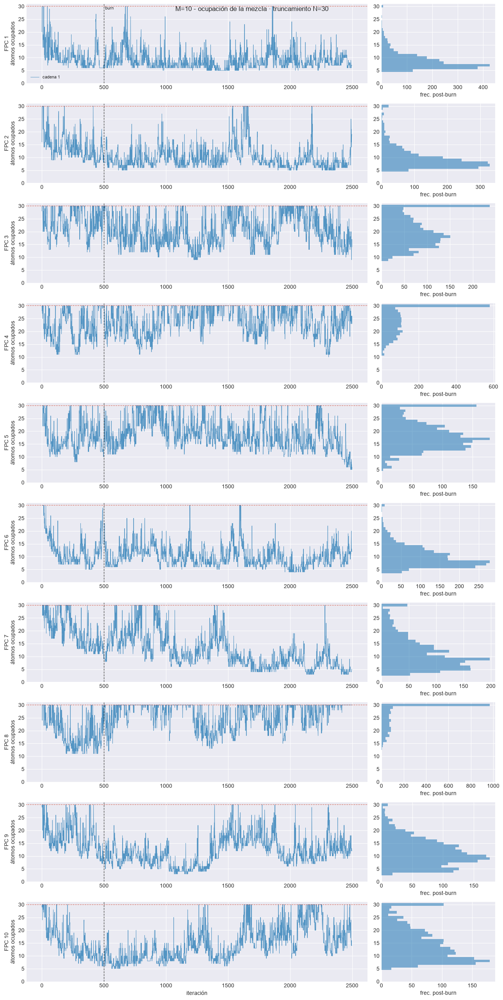

,M,FPC,cadena,media,max,p99,N_trunc,toca_truncamiento,frac_en_N
0,10,1,1,8.76,30,21.0,30,True,0.30%
1,10,2,1,9.66,30,30.0,30,True,1.10%
2,10,3,1,20.13,30,30.0,30,True,11.85%
3,10,4,1,24.34,30,30.0,30,True,29.00%
4,10,5,1,18.72,30,30.0,30,True,7.80%
5,10,6,1,9.91,30,23.0,30,True,0.40%
6,10,7,1,11.42,30,30.0,30,True,2.35%
7,10,8,1,26.33,30,30.0,30,True,48.45%
8,10,9,1,11.50,30,27.0,30,True,0.50%
9,10,10,1,14.61,30,30.0,30,True,5.15%


In [6]:
for M in M_OK:
    e = EST[M]
    ocup_df = ocupacion_mezcla(e, M)
    plot_ocupacion_mezcla(e, M, e["paths"]["out_report"] / "41_ocupacion_mezcla.png")
    plt.show()
    display(ocup_df.style.format({"media": "{:.2f}", "p99": "{:.1f}", "frac_en_N": "{:.2%}"})
            .set_caption(f"M={M} - átomos ocupados post-calentamiento"))

### 4.1 Gating: $\psi$, $\alpha$, $\Gamma$

Promedios ponderados por el peso medio de cada átomo, $\bar w_h=\frac1n\sum_i\pi_h(x_i)$,
para que no dependan del etiquetado. **Señal de gating** = átomos efectivos
globales menos por punto (≈ 0 si los pesos son los mismos en todo $x$);
**sd del argumento** = dispersión en $i$ de $\alpha_h-\sum_j\psi_{hj}|x_{ij}-\Gamma_{hj}|$.

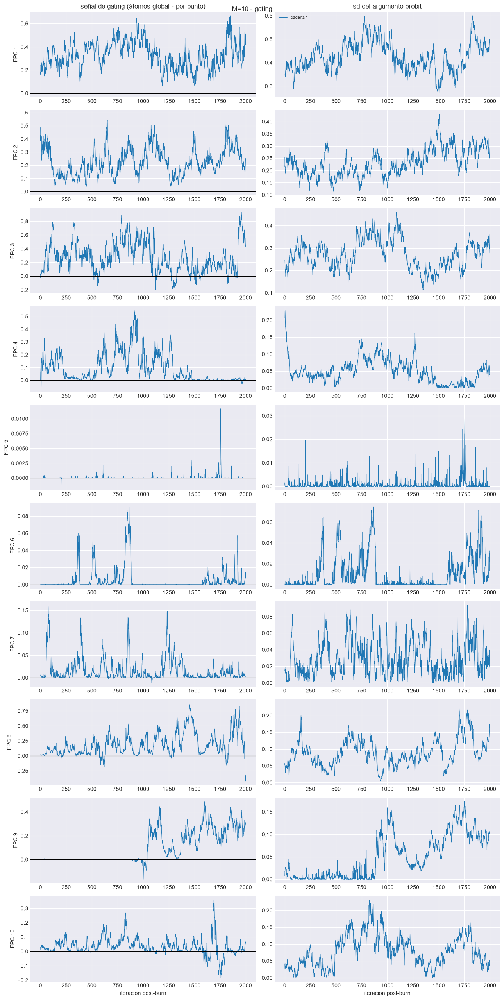

,M,FPC,variable,media_c1,n_cadenas,n_post,ess_min,ess_mean,geweke_max,rhat,converge
0,10,1,atomos_global,3.108,1,2000,13,13,1.307,nan,False
1,10,1,atomos_punto,2.779,1,2000,6,6,1.277,nan,False
2,10,1,senal_gating,0.329,1,2000,13,13,0.667,nan,False
3,10,1,sd_argumento,0.426,1,2000,11,11,1.627,nan,False
4,10,1,alpha,2.240,1,2000,11,11,2.310,nan,False
5,10,1,psi_0,0.241,1,2000,23,23,0.484,nan,False
6,10,1,psi_1,0.343,1,2000,42,42,1.391,nan,False
7,10,1,psi_2,0.655,1,2000,7,7,3.787,nan,False
8,10,1,psi_3,1.037,1,2000,62,62,0.677,nan,False
9,10,1,psi_4,1.041,1,2000,32,32,0.327,nan,False


In [7]:
_CACHE_GATING = {}      # clave (M, componente, cadena): las series cuestan

for M in M_OK:
    e = EST[M]
    gat, series = diagnostico_gating(e, M, _CACHE_GATING)
    plot_gating(series, e, M, e["paths"]["out_report"] / "49_gating.png")
    plt.show()
    display(gat.style.format({c: "{:.3f}" for c in gat.columns
                              if c.startswith("media_") or c in ("rhat", "geweke_max")}
                             | {"ess_min": "{:.0f}", "ess_mean": "{:.0f}"})
            .set_caption(f"M={M} - gating post-calentamiento"))

## 5. Figuras de convergencia por parámetro

== M=10 ==============================================


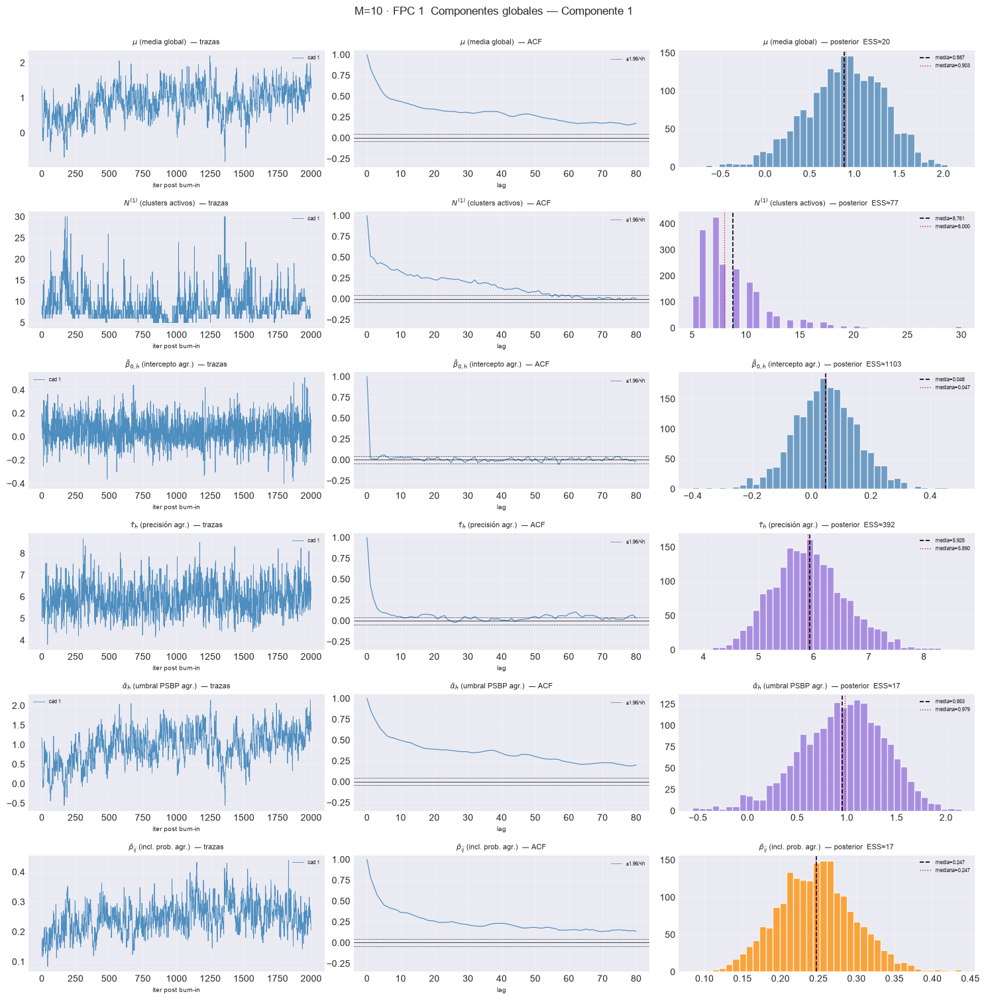

C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_global_components.py:276: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_global_components.py:278: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")


C:\Users\56jua\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


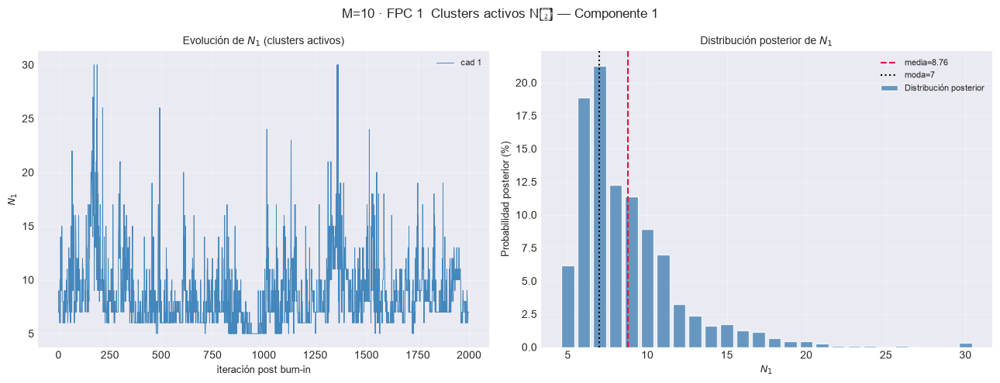

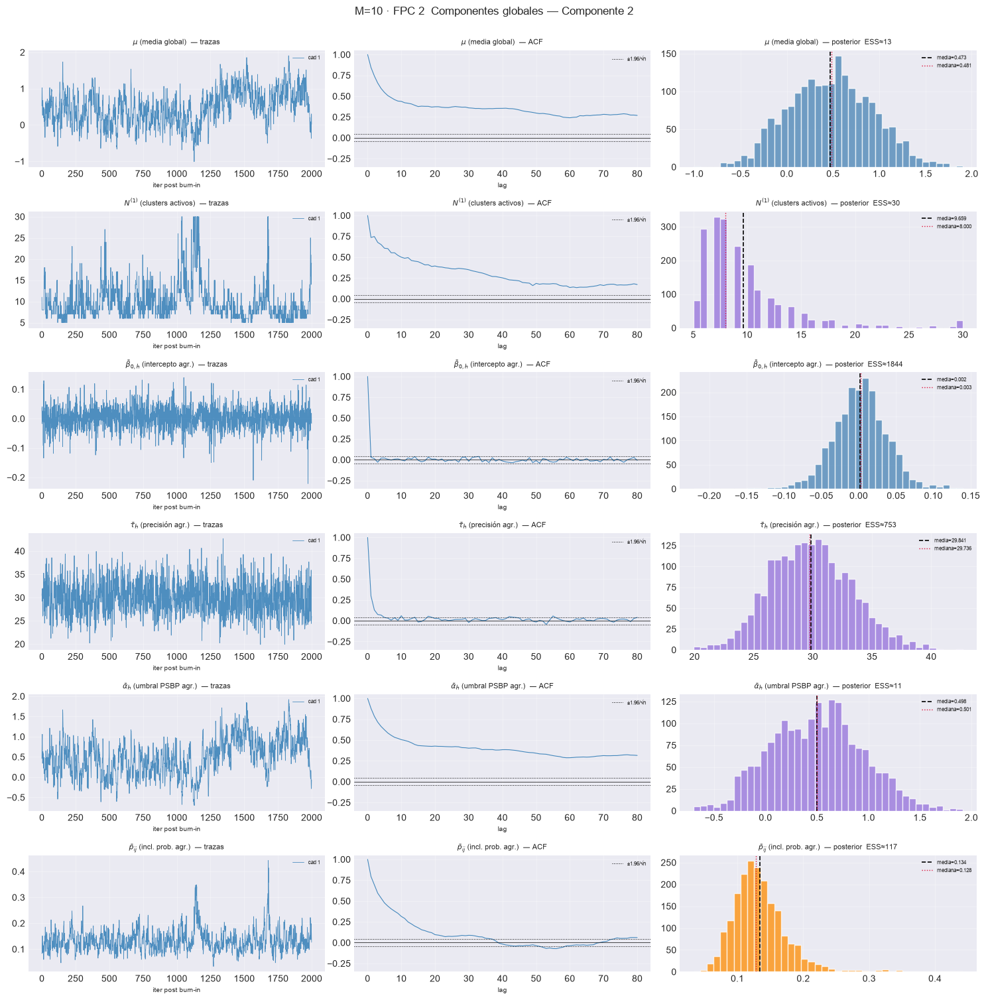

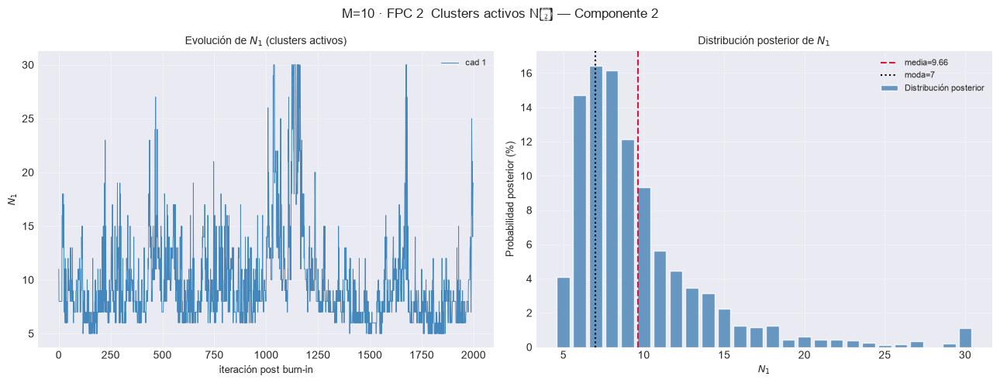

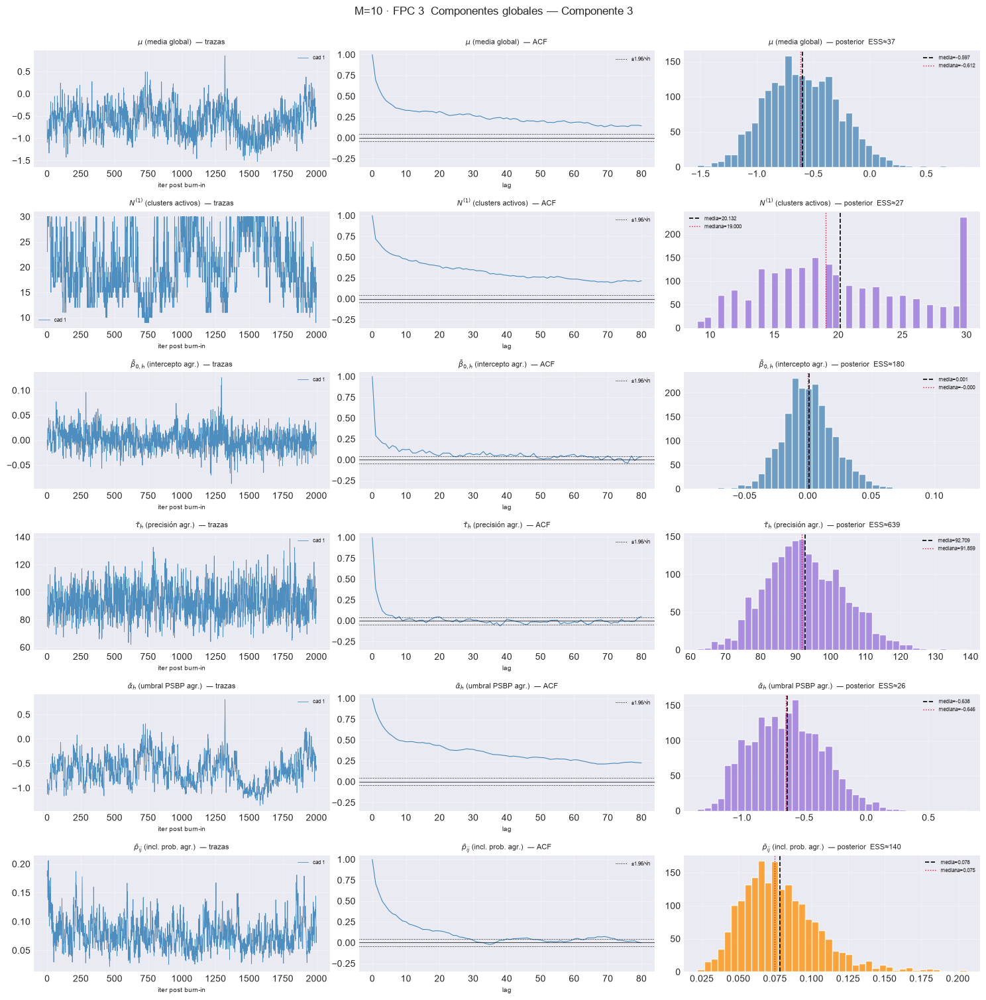

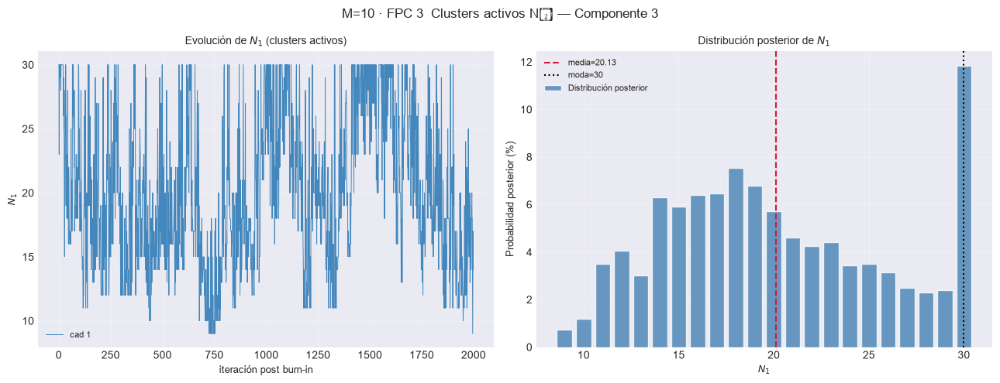

...

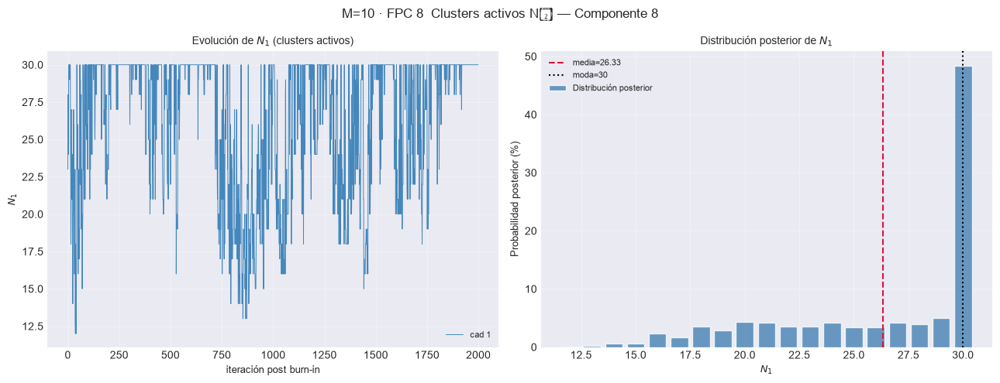

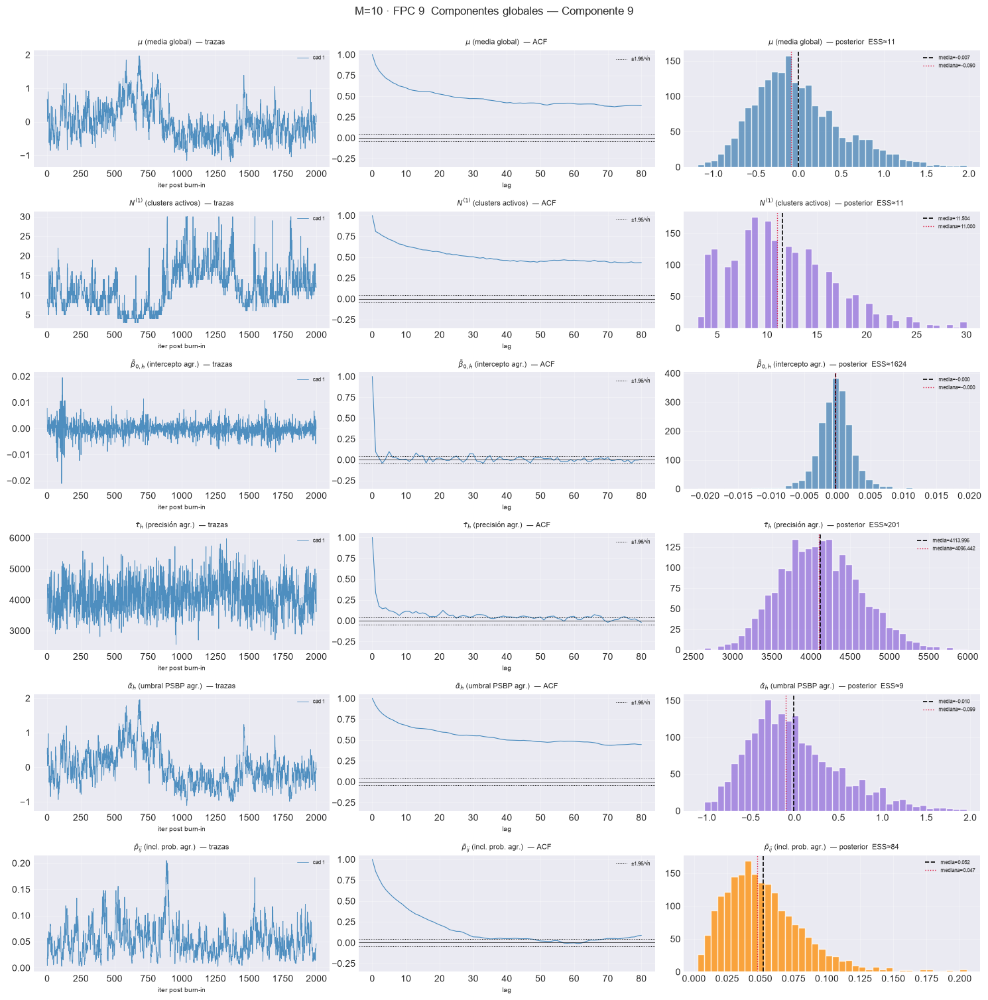

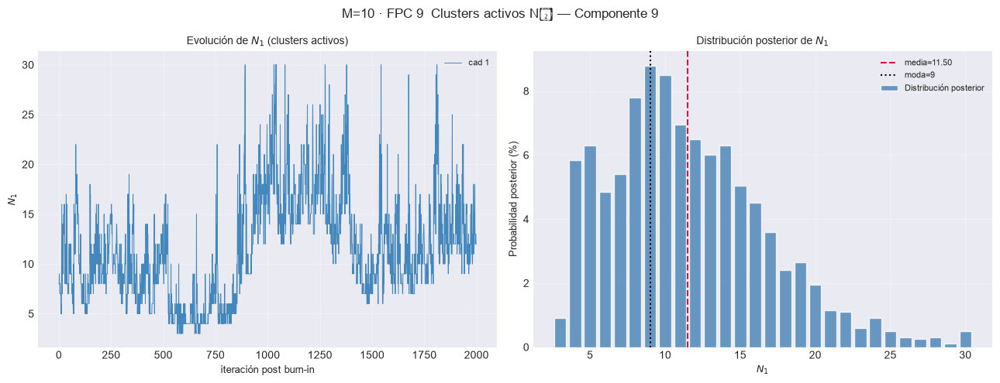

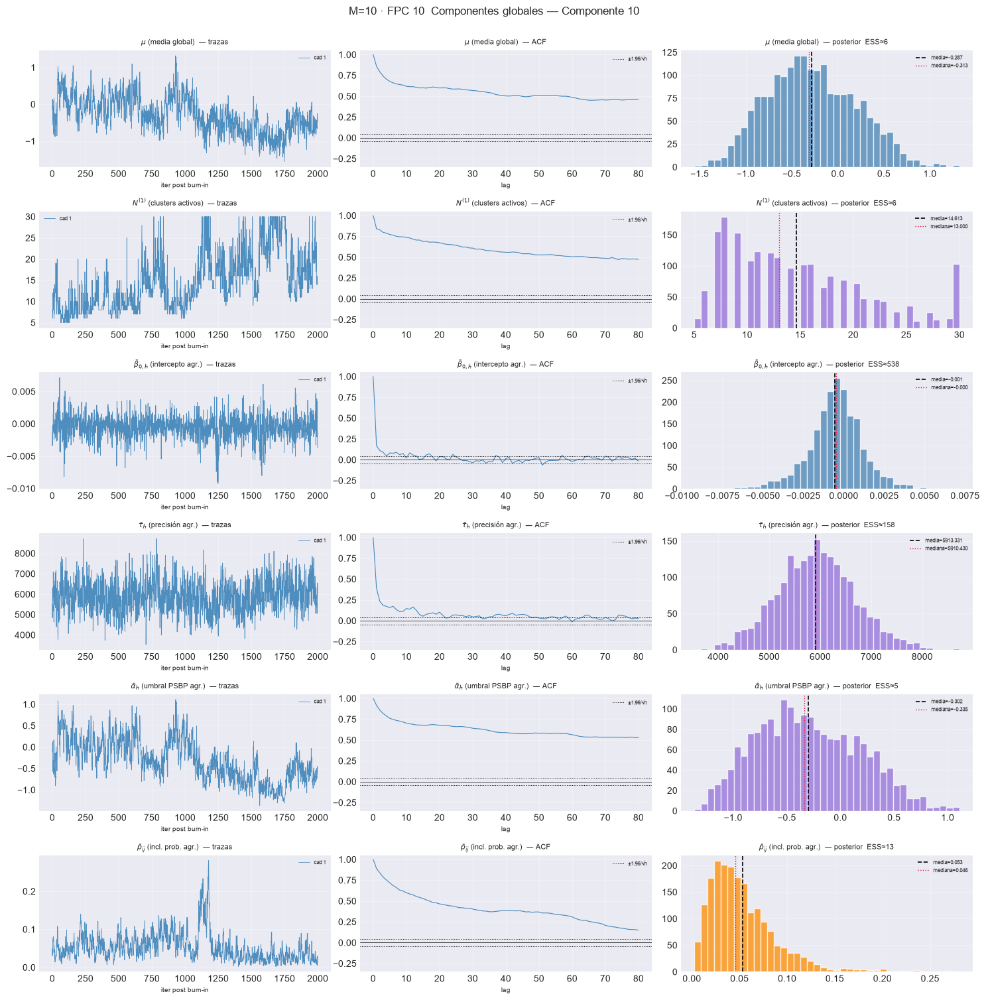

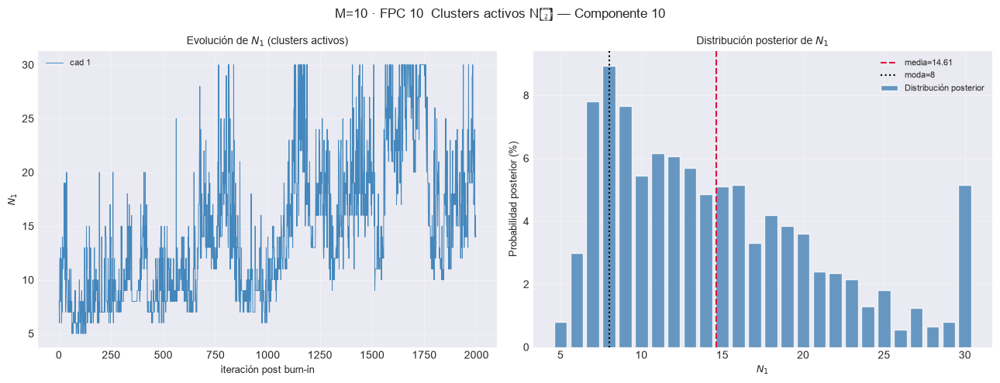

In [8]:
for M in M_OK:
    e = EST[M]
    print(f"== M={M} " + "=" * 46)
    for k in e["models_chains"]:
        fpc = e["component_idx"][k] + 1
        args = (e["models_chains"], k, e["burn"], e["n_iter"])
        plot_global_components(*args, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"42_global_k{fpc}.png"))
        plt.show()
        plot_active_clusters(*args, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"43_clusters_k{fpc}.png"))
        plt.show()

== M=10 ==============================================
[plot_convergence_bj[FPC 1]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=1955  |G|=1.63  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1945  |G|=0.95  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=2000  |G|=0.37  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=1931  |G|=0.09  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=1605  |G|=1.97  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=1270  |G|=0.49  ✓


  7/10 (70.0%) t=0.1s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=2000  |G|=0.68  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=1951  |G|=1.13  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=1772  |G|=2.52  ✗


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=2000  |G|=3.28  ✗


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:348: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:348: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:350: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:350: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")


[plot_convergence_bj[FPC 1]] listo: 10 pasos en 3.5s  2/10 sin converger


C:\Users\56jua\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


C:\Users\56jua\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


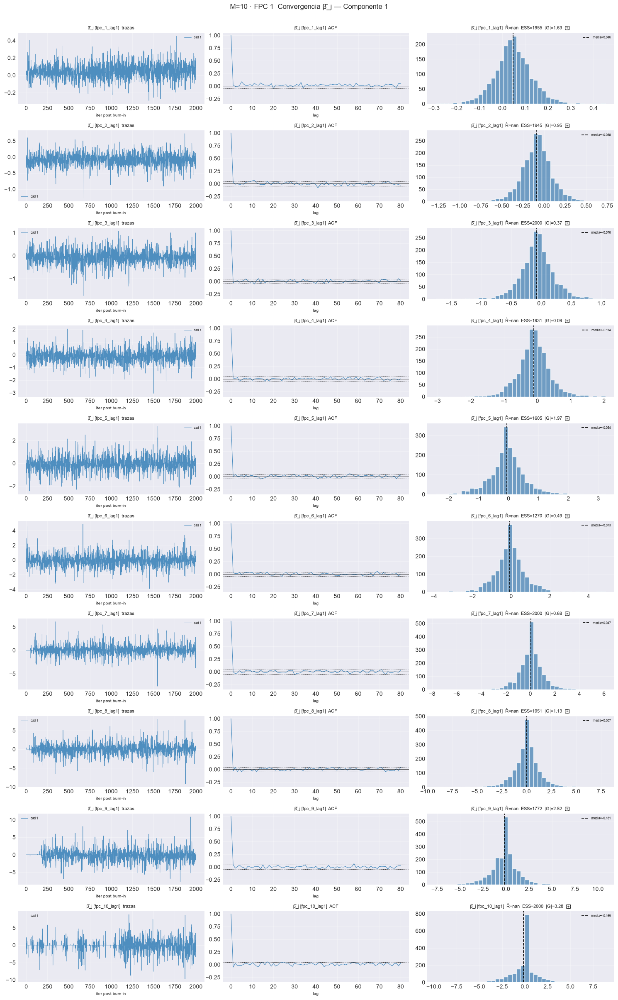

[plot_convergence_pj[FPC 1]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=20  |G|=5.04  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=120  |G|=1.96  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=25  |G|=0.10  ✗


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=308  |G|=0.29  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=428  |G|=0.26  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=315  |G|=0.16  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=141  |G|=1.99  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=172  |G|=1.55  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=50  |G|=7.10  ✗


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=8  |G|=3.03  ✗


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:447: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:447: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()


C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:449: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")
C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\model_psbp_fd\graphics\viz_traces.py:449: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")


[plot_convergence_pj[FPC 1]] listo: 10 pasos en 3.3s  4/10 sin converger


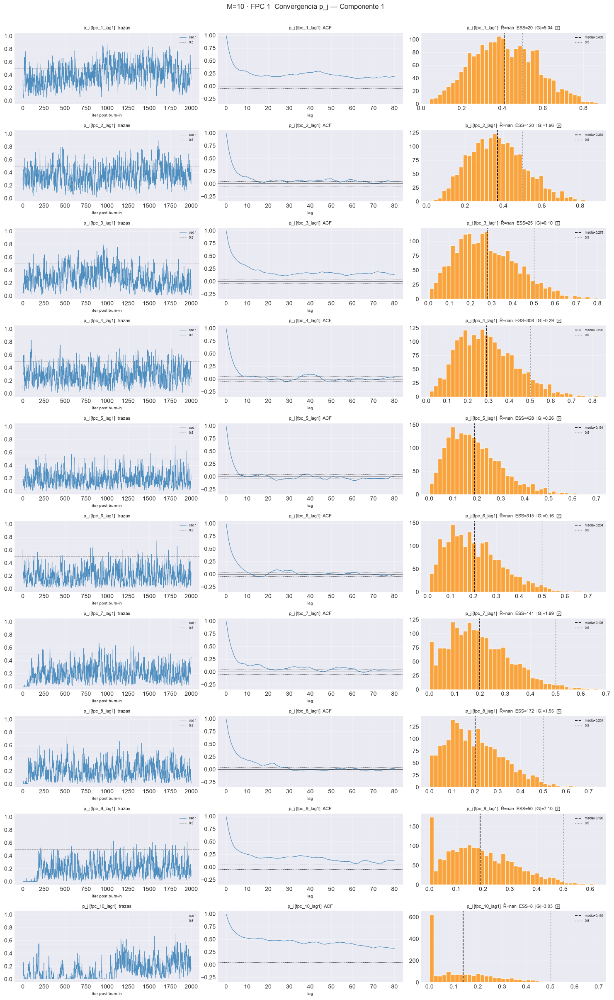

[plot_convergence_bj[FPC 2]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=1363  |G|=2.90  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1045  |G|=1.51  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=1335  |G|=0.31  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=1735  |G|=0.93  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=1159  |G|=0.87  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=1210  |G|=3.04  ✗


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=1551  |G|=0.06  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=1858  |G|=0.93  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=1535  |G|=3.76  ✗


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1598  |G|=1.00  ✓

[plot_convergence_bj[FPC 2]] listo: 10 pasos en 3.5s  3/10 sin converger


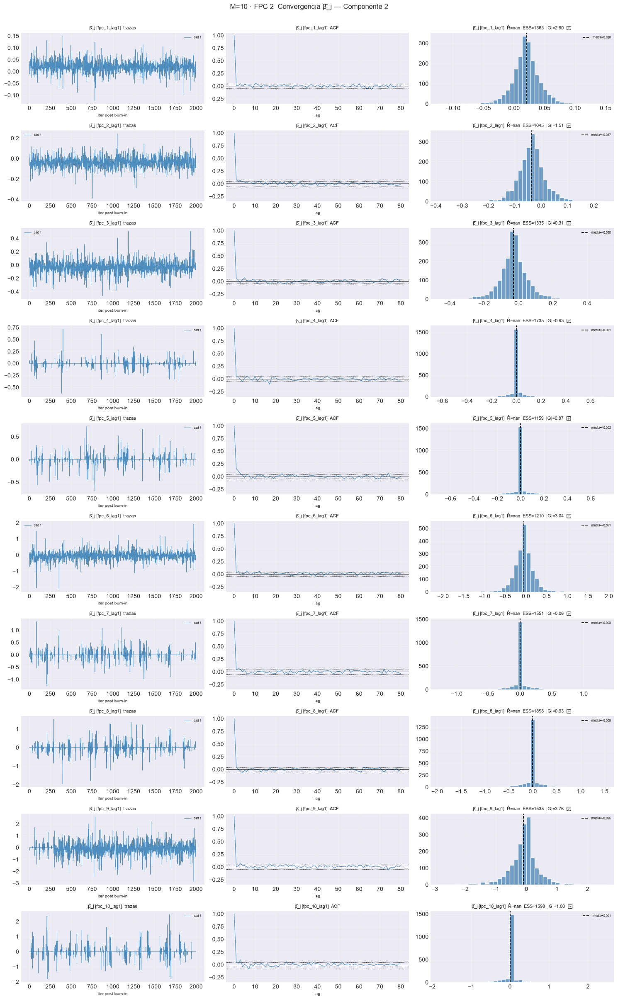

[plot_convergence_pj[FPC 2]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=90  |G|=0.64  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=160  |G|=2.07  ✗


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=214  |G|=0.27  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=121  |G|=0.10  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=132  |G|=0.28  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=150  |G|=1.90  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=146  |G|=0.65  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=152  |G|=1.05  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=37  |G|=7.64  ✗


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=159  |G|=0.38  ✓


[plot_convergence_pj[FPC 2]] listo: 10 pasos en 3.4s  3/10 sin converger


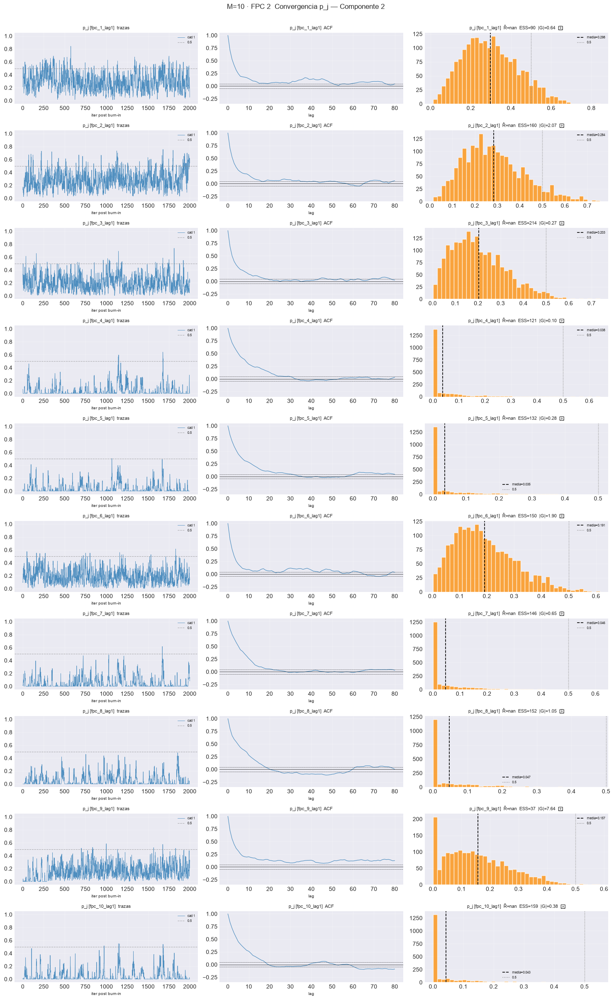

[plot_convergence_bj[FPC 3]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=595  |G|=0.98  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1522  |G|=0.01  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=1495  |G|=0.69  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=2000  |G|=0.41  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=1570  |G|=0.70  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=1820  |G|=1.26  ✓


  7/10 (70.0%) t=0.1s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=2000  |G|=0.20  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=1437  |G|=0.55  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=2000  |G|=1.36  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1054  |G|=0.08  ✓


[plot_convergence_bj[FPC 3]] listo: 10 pasos en 3.4s  0/10 sin converger


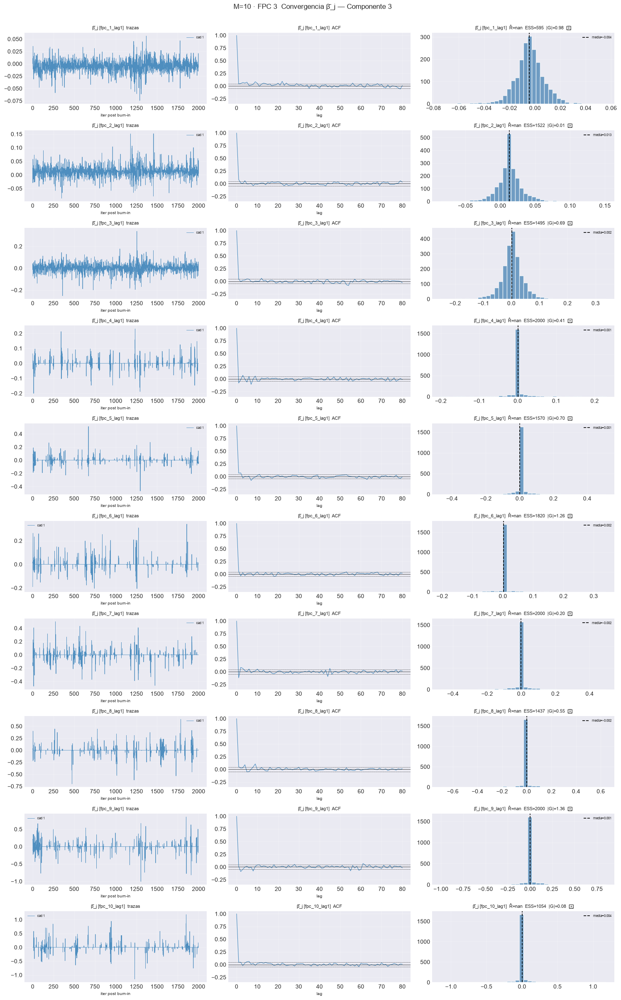

[plot_convergence_pj[FPC 3]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=168  |G|=0.18  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=267  |G|=0.30  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=280  |G|=1.24  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=220  |G|=0.21  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=189  |G|=0.55  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=266  |G|=1.81  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=188  |G|=1.40  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=187  |G|=0.85  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=78  |G|=1.88  ✗


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=145  |G|=2.10  ✗


[plot_convergence_pj[FPC 3]] listo: 10 pasos en 3.2s  2/10 sin converger


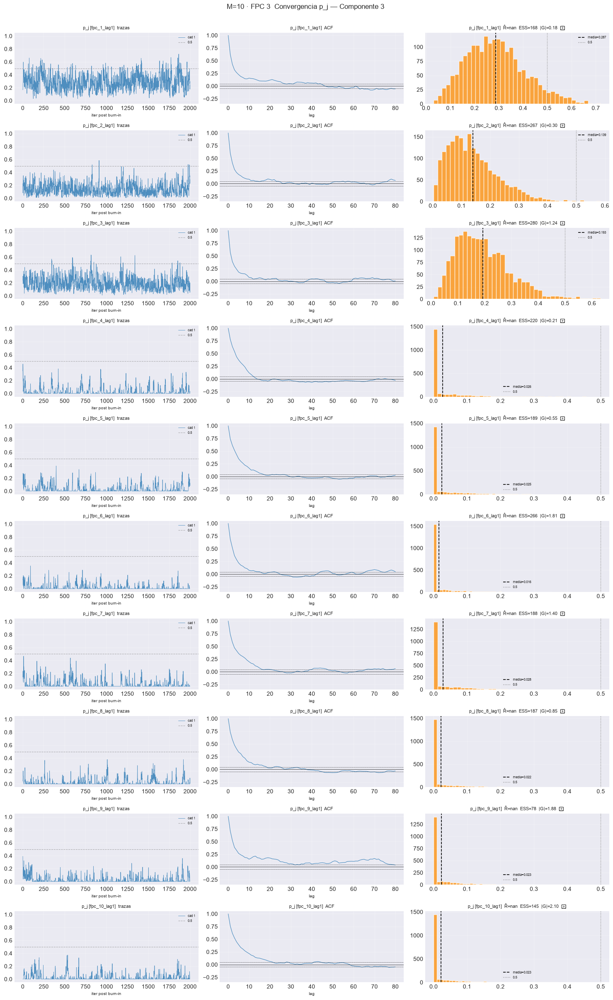

[plot_convergence_bj[FPC 4]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=662  |G|=2.38  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1591  |G|=1.58  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=854  |G|=0.85  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=2000  |G|=0.29  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=2000  |G|=0.42  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=2000  |G|=0.58  ✓


  7/10 (70.0%) t=0.1s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=2000  |G|=1.19  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=1808  |G|=0.02  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=1567  |G|=1.28  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1923  |G|=0.75  ✓


[plot_convergence_bj[FPC 4]] listo: 10 pasos en 3.3s  1/10 sin converger


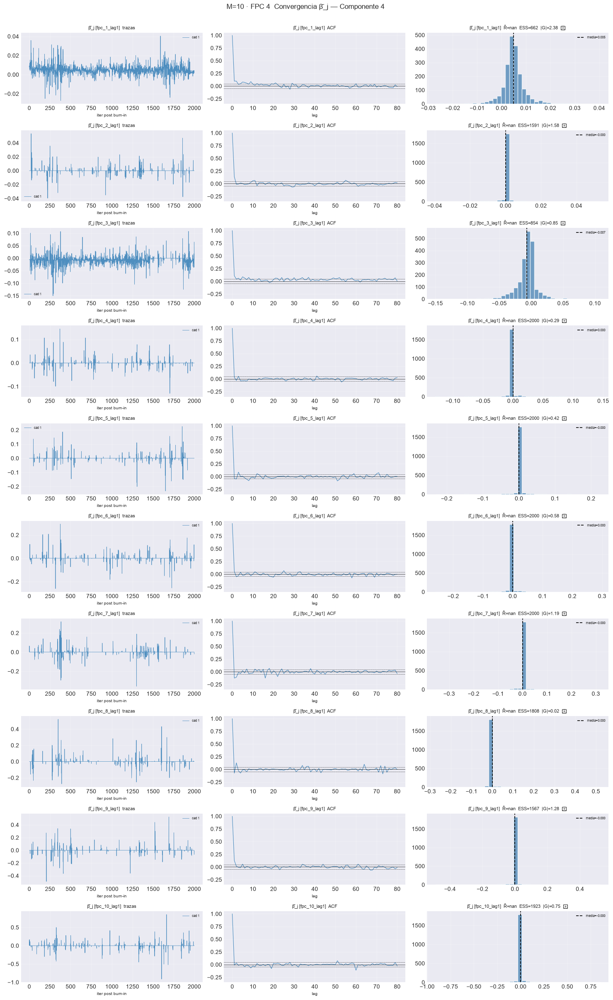

[plot_convergence_pj[FPC 4]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=493  |G|=0.17  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=177  |G|=0.82  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=37  |G|=2.02  ✗


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=345  |G|=0.69  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=300  |G|=1.56  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=238  |G|=0.54  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=235  |G|=0.52  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=176  |G|=0.16  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=406  |G|=0.69  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=463  |G|=0.53  ✓

[plot_convergence_pj[FPC 4]] listo: 10 pasos en 3.1s  1/10 sin converger


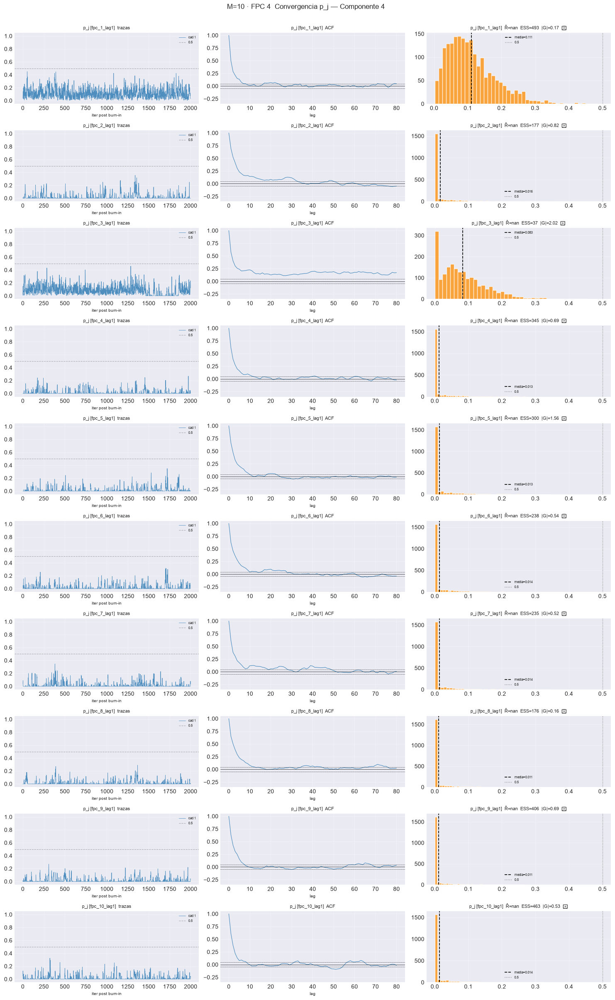

[plot_convergence_bj[FPC 5]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=1912  |G|=2.55  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1846  |G|=0.15  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=2000  |G|=0.31  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=1351  |G|=0.89  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=1356  |G|=1.38  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=1865  |G|=0.46  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=2000  |G|=0.65  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=1707  |G|=0.86  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=2000  |G|=0.04  ✓

  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=2000  |G|=1.82  ✓


[plot_convergence_bj[FPC 5]] listo: 10 pasos en 3.6s  1/10 sin converger


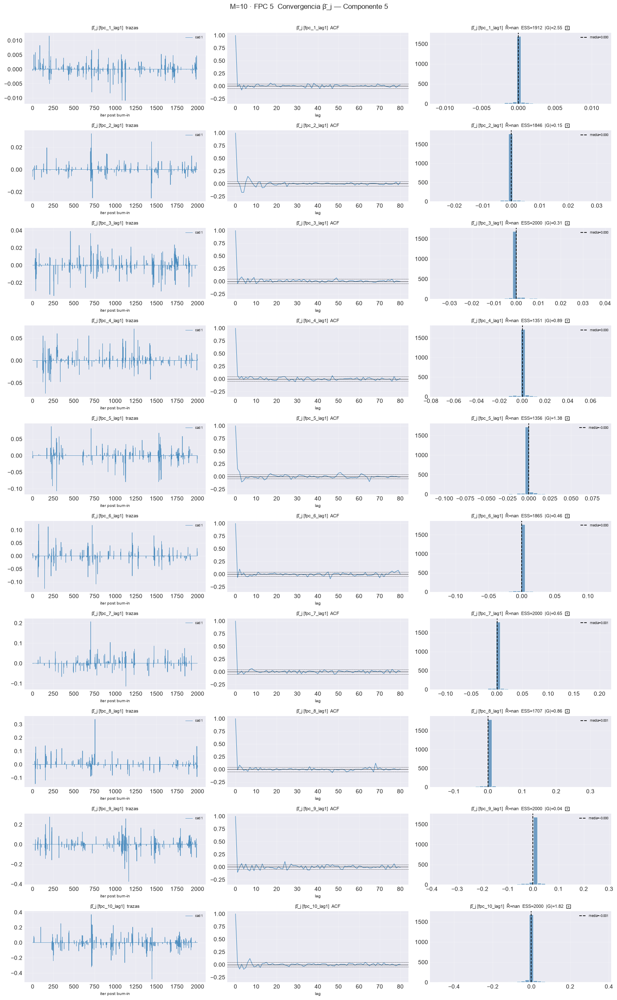

[plot_convergence_pj[FPC 5]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=254  |G|=0.48  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=349  |G|=0.85  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=201  |G|=0.02  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=311  |G|=0.32  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=187  |G|=2.90  ✗


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=348  |G|=0.01  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=409  |G|=1.61  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=351  |G|=0.92  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=148  |G|=0.91  ✓

  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=142  |G|=2.71  ✗


[plot_convergence_pj[FPC 5]] listo: 10 pasos en 3.2s  2/10 sin converger


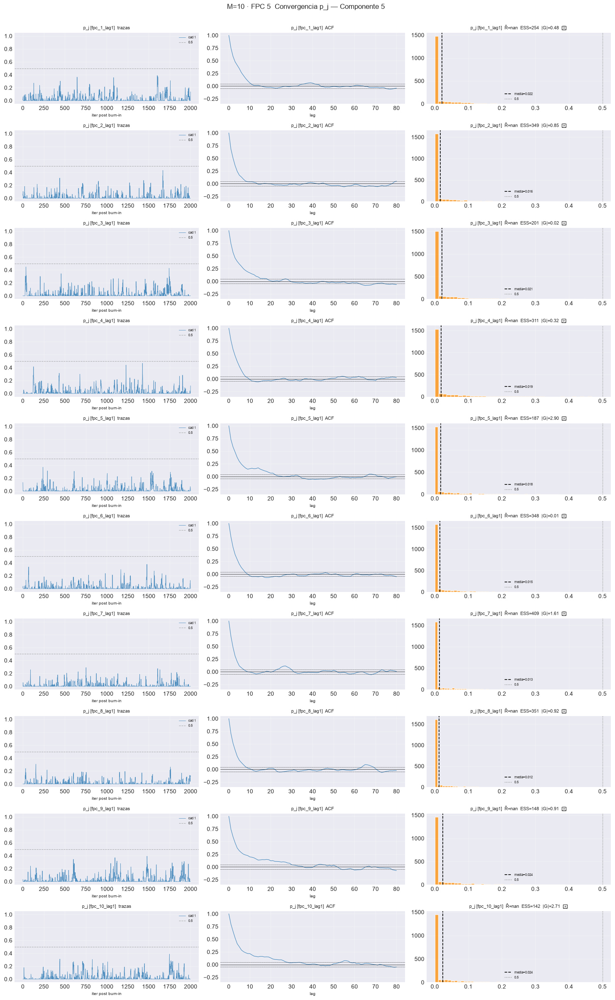

[plot_convergence_bj[FPC 6]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=1874  |G|=0.49  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1232  |G|=1.07  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=1226  |G|=1.25  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=2000  |G|=0.18  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=2000  |G|=0.48  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=2000  |G|=0.24  ✓


  7/10 (70.0%) t=0.1s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=2000  |G|=1.37  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=1850  |G|=0.67  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=2000  |G|=0.81  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=2000  |G|=0.88  ✓

[plot_convergence_bj[FPC 6]] listo: 10 pasos en 3.4s  0/10 sin converger


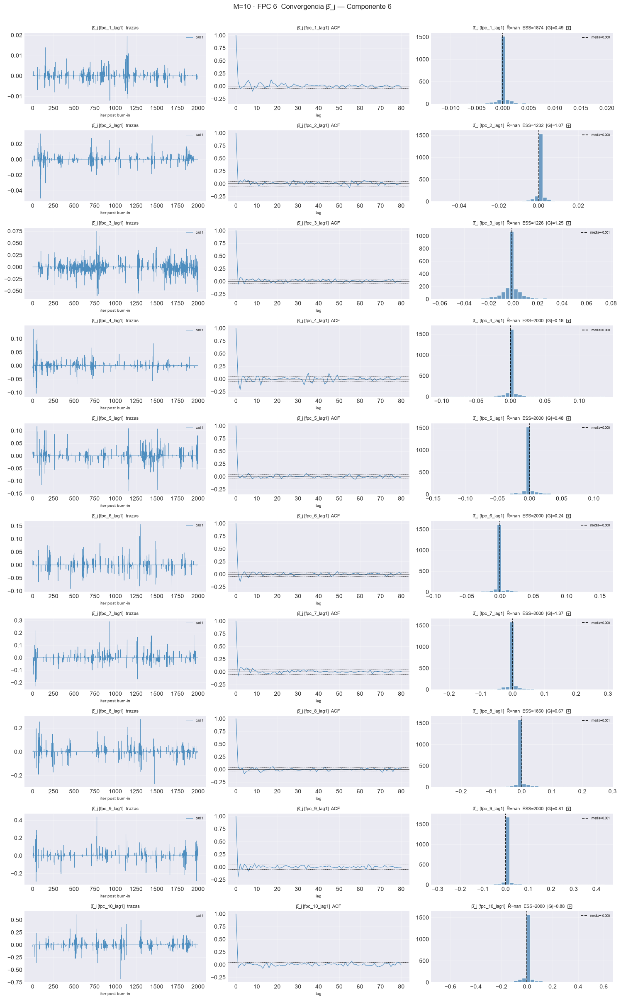

[plot_convergence_pj[FPC 6]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=140  |G|=0.10  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=79  |G|=0.96  ✗


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=18  |G|=1.69  ✗


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=116  |G|=2.35  ✗


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=112  |G|=0.48  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=179  |G|=0.19  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=209  |G|=0.20  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=154  |G|=0.55  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=139  |G|=0.53  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=141  |G|=1.15  ✓


[plot_convergence_pj[FPC 6]] listo: 10 pasos en 3.2s  3/10 sin converger


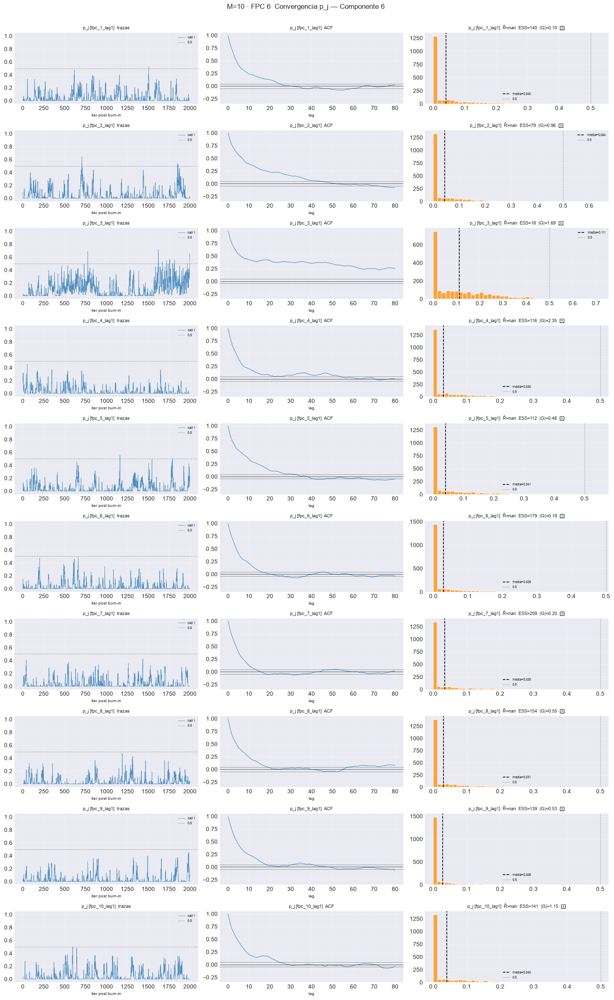

[plot_convergence_bj[FPC 7]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=2000  |G|=0.71  ✓


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1437  |G|=0.24  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=1817  |G|=0.17  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=2000  |G|=0.69  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=2000  |G|=1.29  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=2000  |G|=1.34  ✓


  7/10 (70.0%) t=0.1s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=1708  |G|=1.57  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=1625  |G|=0.69  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=2000  |G|=0.08  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1554  |G|=1.13  ✓


[plot_convergence_bj[FPC 7]] listo: 10 pasos en 3.4s  0/10 sin converger


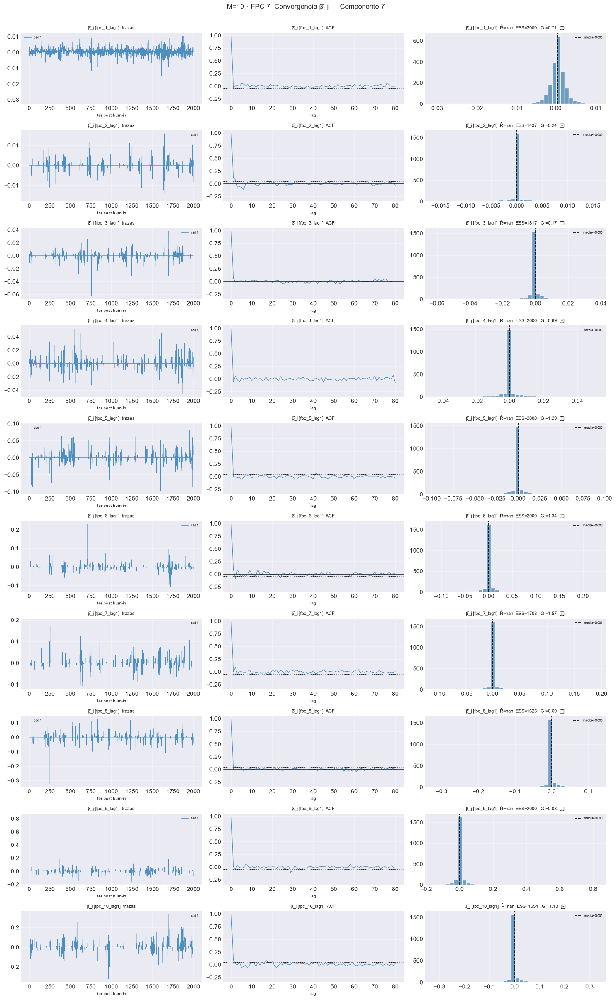

[plot_convergence_pj[FPC 7]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=85  |G|=5.79  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=169  |G|=0.73  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=83  |G|=2.48  ✗


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=138  |G|=0.58  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=94  |G|=2.01  ✗


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=83  |G|=1.53  ✗


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=155  |G|=2.89  ✗


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=208  |G|=2.51  ✗


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=85  |G|=1.82  ✗


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=109  |G|=0.98  ✓

[plot_convergence_pj[FPC 7]] listo: 10 pasos en 3.2s  7/10 sin converger


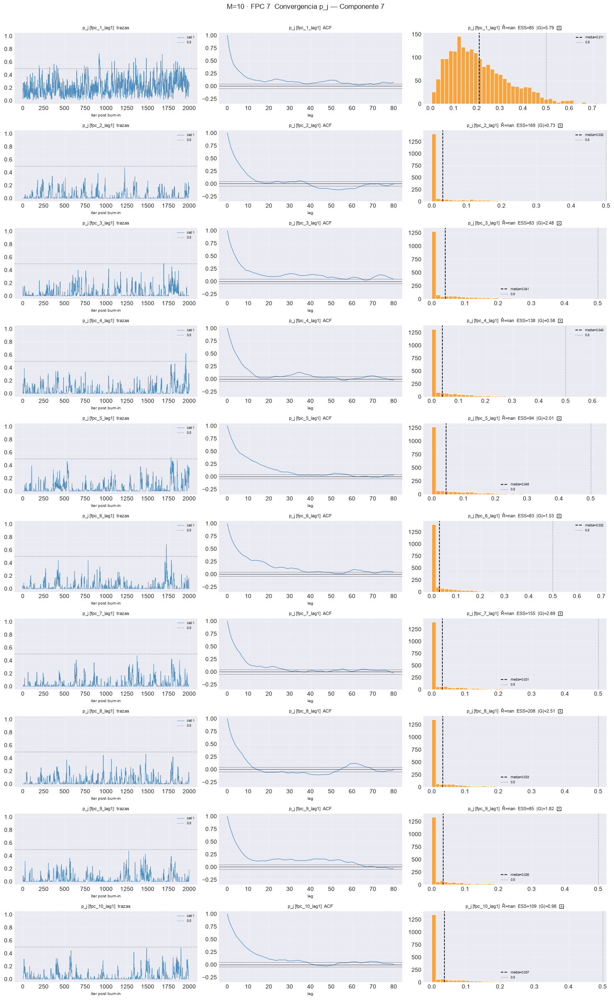

[plot_convergence_bj[FPC 8]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=251  |G|=3.70  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1435  |G|=1.88  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=1791  |G|=0.57  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=1715  |G|=0.25  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=2000  |G|=1.33  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=1749  |G|=0.15  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=1890  |G|=1.47  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=1904  |G|=1.75  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=856  |G|=0.86  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=2000  |G|=0.00  ✓

[plot_convergence_bj[FPC 8]] listo: 10 pasos en 3.4s  1/10 sin converger


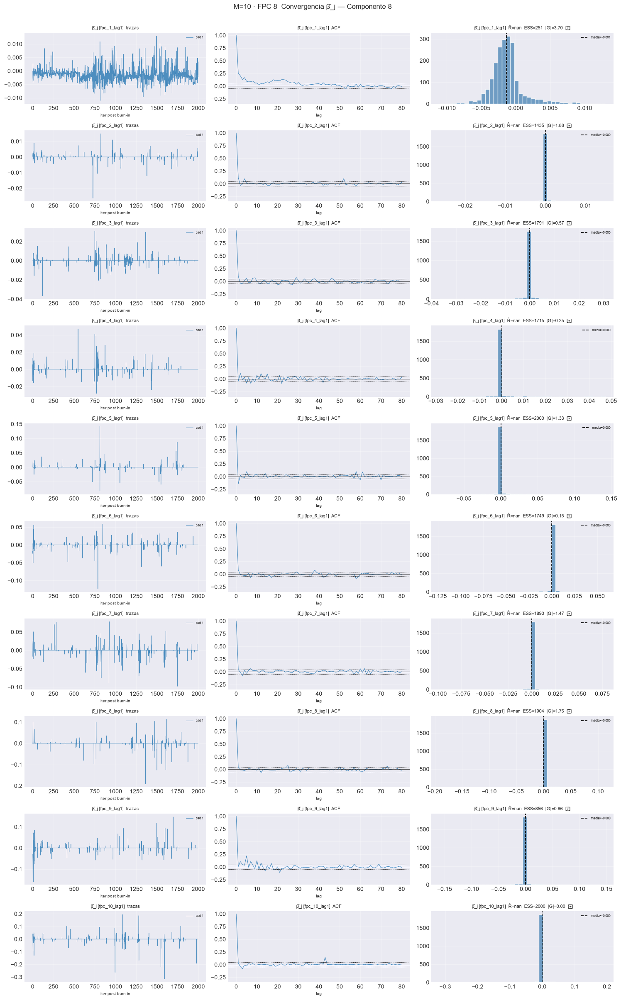

[plot_convergence_pj[FPC 8]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=52  |G|=1.38  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=303  |G|=1.65  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=77  |G|=0.23  ✗


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=151  |G|=1.65  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=309  |G|=0.74  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=317  |G|=0.30  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=309  |G|=0.36  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=556  |G|=0.10  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=157  |G|=1.35  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=254  |G|=0.92  ✓


[plot_convergence_pj[FPC 8]] listo: 10 pasos en 3.1s  2/10 sin converger


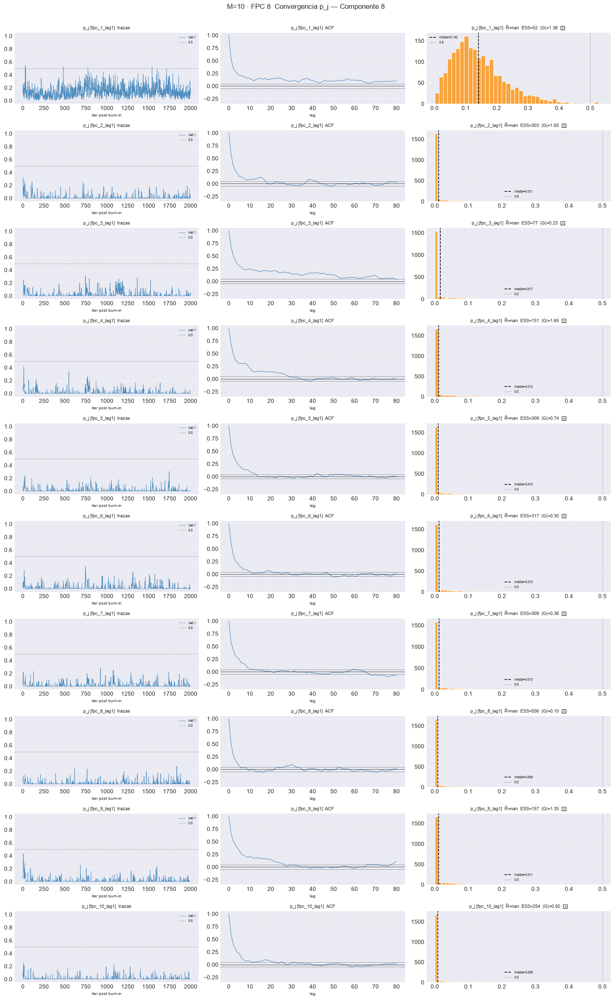

[plot_convergence_bj[FPC 9]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=1571  |G|=5.17  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1865  |G|=0.63  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=1046  |G|=1.01  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=2000  |G|=0.46  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=2000  |G|=0.61  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=212  |G|=1.16  ✓


  7/10 (70.0%) t=0.1s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=1430  |G|=1.26  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=67  |G|=1.08  ✗


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=2000  |G|=0.51  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=2000  |G|=1.14  ✓

[plot_convergence_bj[FPC 9]] listo: 10 pasos en 3.4s  2/10 sin converger


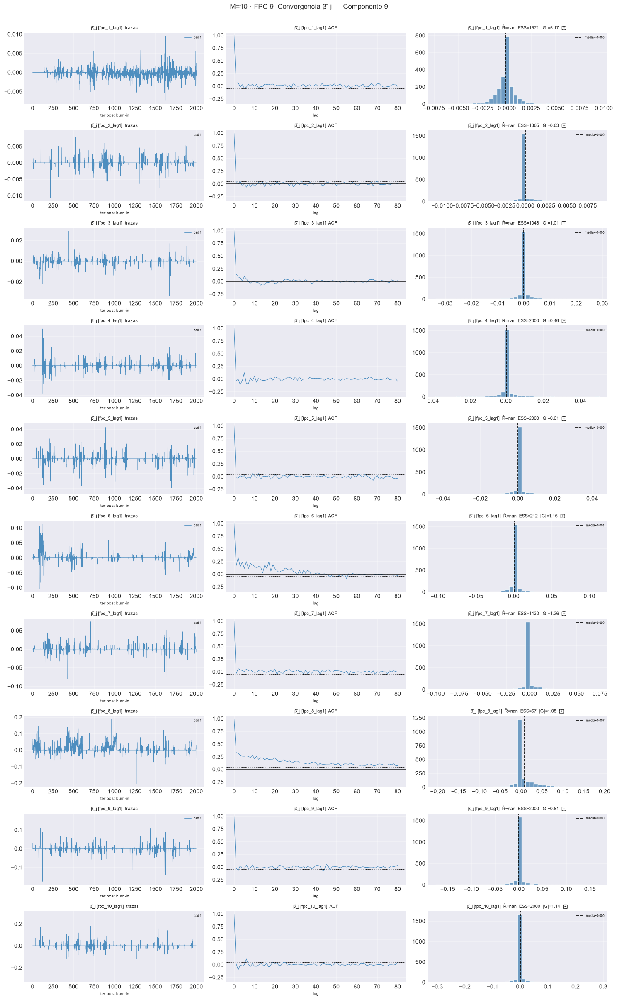

[plot_convergence_pj[FPC 9]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=18  |G|=9.39  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=101  |G|=2.62  ✗


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=116  |G|=1.58  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=139  |G|=0.52  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=182  |G|=1.92  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=78  |G|=1.70  ✗


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=137  |G|=0.33  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=33  |G|=1.16  ✗


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=217  |G|=1.20  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=116  |G|=0.33  ✓


[plot_convergence_pj[FPC 9]] listo: 10 pasos en 3.2s  4/10 sin converger


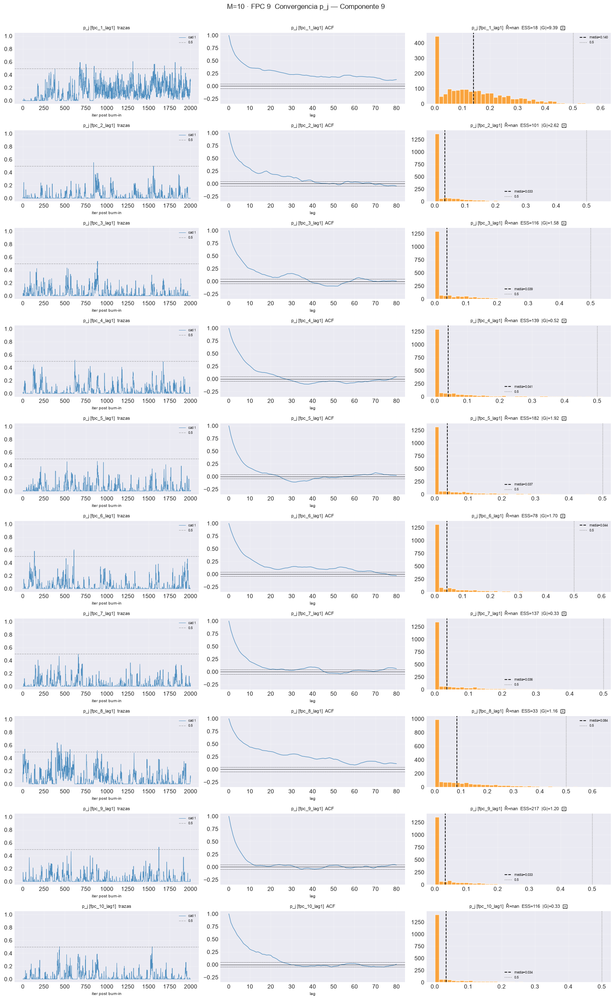

[plot_convergence_bj[FPC 10]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=564  |G|=3.26  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=1966  |G|=1.14  ✓


  3/10 (30.0%) t=0.1s eta=0.1s  fpc_3_lag1  rhat=nan  ess_min=680  |G|=0.27  ✓


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=2000  |G|=1.45  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=1630  |G|=0.13  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=2000  |G|=1.34  ✓


  7/10 (70.0%) t=0.2s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=2000  |G|=0.13  ✓


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=2000  |G|=0.73  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=1611  |G|=0.05  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=1324  |G|=0.29  ✓


[plot_convergence_bj[FPC 10]] listo: 10 pasos en 3.4s  1/10 sin converger


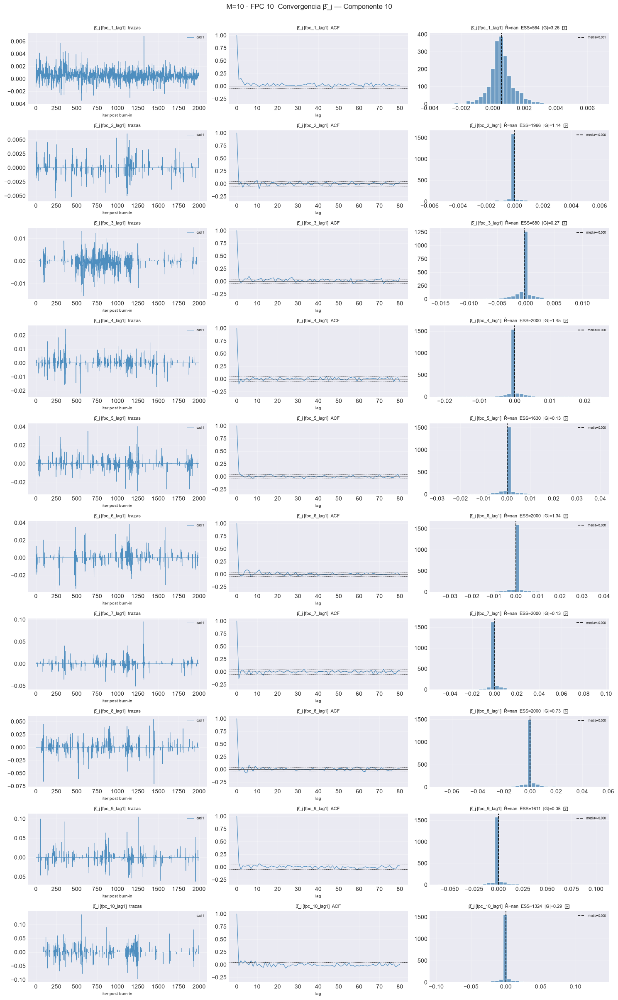

[plot_convergence_pj[FPC 10]] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.2s  fpc_1_lag1  rhat=nan  ess_min=46  |G|=1.57  ✗


  2/10 (20.0%) t=0.0s eta=0.2s  fpc_2_lag1  rhat=nan  ess_min=159  |G|=0.35  ✓


  3/10 (30.0%) t=0.1s eta=0.2s  fpc_3_lag1  rhat=nan  ess_min=9  |G|=0.22  ✗


  4/10 (40.0%) t=0.1s eta=0.1s  fpc_4_lag1  rhat=nan  ess_min=109  |G|=0.45  ✓


  5/10 (50.0%) t=0.1s eta=0.1s  fpc_5_lag1  rhat=nan  ess_min=112  |G|=0.77  ✓


  6/10 (60.0%) t=0.1s eta=0.1s  fpc_6_lag1  rhat=nan  ess_min=147  |G|=0.44  ✓


  7/10 (70.0%) t=0.1s eta=0.1s  fpc_7_lag1  rhat=nan  ess_min=76  |G|=1.32  ✗


  8/10 (80.0%) t=0.2s eta=0.0s  fpc_8_lag1  rhat=nan  ess_min=162  |G|=0.56  ✓


  9/10 (90.0%) t=0.2s eta=0.0s  fpc_9_lag1  rhat=nan  ess_min=100  |G|=0.73  ✓


  10/10 (100.0%) t=0.2s eta=0.0s  fpc_10_lag1  rhat=nan  ess_min=50  |G|=0.72  ✗


[plot_convergence_pj[FPC 10]] listo: 10 pasos en 3.2s  4/10 sin converger


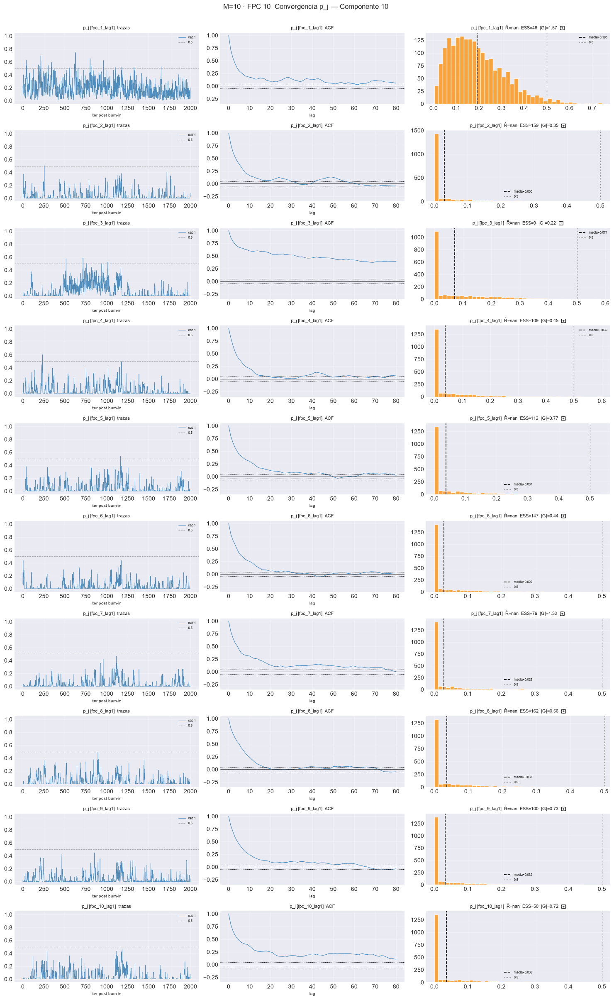

In [9]:
# Traza | ACF | posterior con las métricas anotadas; beta_j va promediado sobre
# átomos (invariante a la permutación de etiquetas). verbose=True saca
# Rhat/ESS/Geweke por covariable a la consola.
for M in M_OK:
    e = EST[M]
    print(f"== M={M} " + "=" * 46)
    for k in e["models_chains"]:
        fpc  = e["component_idx"][k] + 1
        feat = e["models_chains"][k][0].feature_names_
        args = (e["models_chains"], k, e["burn"], e["n_iter"])
        plot_convergence_bj(*args, feature_names=feat, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"44_conv_bj_k{fpc}.png"), verbose=True)
        plt.show()
        plot_convergence_pj(*args, feature_names=feat, title_prefix=f"M={M} · FPC {fpc}",
            save_path=str(e["paths"]["out_report"] / f"45_conv_pj_k{fpc}.png"), verbose=True)
        plt.show()

## 6. Probabilidades posteriores de inclusión

Tercer eje del diseño (`docs §03_06`): qué variables selecciona el modelo.
Con datos reales no hay estructura verdadera contra la cual contrastar: se reporta
el PIP y su dispersión entre cadenas.

In [10]:
for M in M_OK:
    pip_df = pip_punto(EST[M], SD_PIP_MAX)
    display(pip_df.style
        .background_gradient(subset=[c for c in pip_df.columns if not c.endswith("_sd")],
                             cmap="RdYlGn", vmin=0, vmax=1)
        .format("{:.3f}")
        .set_caption(f"M={M} - P(gamma_j = 1 | datos), inclusión global, media entre cadenas +- sd"))

[matriz_pip] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  FPC 1: 1 cadenas, 10 variables, PIP en [0.578, 1.000]


  2/10 (20.0%) t=0.0s eta=0.0s  FPC 2: 1 cadenas, 10 variables, PIP en [0.132, 1.000]


  3/10 (30.0%) t=0.0s eta=0.0s  FPC 3: 1 cadenas, 10 variables, PIP en [0.110, 1.000]


  4/10 (40.0%) t=0.0s eta=0.0s  FPC 4: 1 cadenas, 10 variables, PIP en [0.080, 1.000]


  5/10 (50.0%) t=0.0s eta=0.0s  FPC 5: 1 cadenas, 10 variables, PIP en [0.064, 0.130]


  6/10 (60.0%) t=0.0s eta=0.0s  FPC 6: 1 cadenas, 10 variables, PIP en [0.092, 0.528]


  7/10 (70.0%) t=0.0s eta=0.0s  FPC 7: 1 cadenas, 10 variables, PIP en [0.113, 1.000]


  8/10 (80.0%) t=0.0s eta=0.0s  FPC 8: 1 cadenas, 10 variables, PIP en [0.061, 1.000]


  9/10 (90.0%) t=0.0s eta=0.0s  FPC 9: 1 cadenas, 10 variables, PIP en [0.111, 0.693]


  10/10 (100.0%) t=0.0s eta=0.0s  FPC 10: 1 cadenas, 10 variables, PIP en [0.136, 1.000]


[matriz_pip] listo: 10 pasos en 0.0s  tabla 10x20


[M=10] dispersion maxima entre cadenas: 0.000   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd,FPC 8,FPC 8_sd,FPC 9,FPC 9_sd,FPC 10,FPC 10_sd
variable,,,,,,,,,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,0.130,0.000,0.149,0.000,1.000,0.000,1.000,0.000,0.693,0.000,1.000,0.000
fpc_2_lag1,1.000,0.000,1.000,0.000,1.000,0.000,0.120,0.000,0.098,0.000,0.167,0.000,0.122,0.000,0.088,0.000,0.150,0.000,0.136,0.000
fpc_3_lag1,1.000,0.000,1.000,0.000,1.000,0.000,0.839,0.000,0.124,0.000,0.528,0.000,0.154,0.000,0.136,0.000,0.163,0.000,0.377,0.000
fpc_4_lag1,1.000,0.000,0.138,0.000,0.168,0.000,0.098,0.000,0.108,0.000,0.117,0.000,0.151,0.000,0.079,0.000,0.141,0.000,0.178,0.000
fpc_5_lag1,1.000,0.000,0.132,0.000,0.168,0.000,0.104,0.000,0.107,0.000,0.147,0.000,0.177,0.000,0.077,0.000,0.154,0.000,0.160,0.000
fpc_6_lag1,1.000,0.000,1.000,0.000,0.110,0.000,0.095,0.000,0.085,0.000,0.109,0.000,0.131,0.000,0.097,0.000,0.184,0.000,0.148,0.000
fpc_7_lag1,0.960,0.000,0.169,0.000,0.180,0.000,0.099,0.000,0.078,0.000,0.121,0.000,0.113,0.000,0.101,0.000,0.137,0.000,0.145,0.000
fpc_8_lag1,0.970,0.000,0.190,0.000,0.140,0.000,0.088,0.000,0.064,0.000,0.104,0.000,0.129,0.000,0.061,0.000,0.338,0.000,0.166,0.000
fpc_9_lag1,0.913,0.000,0.875,0.000,0.170,0.000,0.080,0.000,0.121,0.000,0.092,0.000,0.143,0.000,0.085,0.000,0.111,0.000,0.151,0.000


## 7. Verificación muestreador ↔ predictor

`inEout` es $E[y\mid x]$ dentro de muestra tal como la calcula MATLAB en cada
iteración. Debe coincidir con lo que el predictor de Python reconstruye de las
mismas trazas: es la única prueba directa de que ambos lados interpretan las
trazas igual. Se corre **en cada $M$** (el contrato depende de $p$).

In [11]:
ok_global = all([verificar_muestreador_predictor(EST[M], CORR_MIN_CONTRATO) for M in M_OK])
print(f"\n{'OK contrato verificado en todo el barrido' if ok_global else 'X el contrato falla'}")

-- M=10 --


  FPC 1 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 2 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 3 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 4 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 5 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 6 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 7 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 8 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 9 cadena1: corr=1.000000  |dif|max=0.0000


  FPC 10 cadena1: corr=1.000000  |dif|max=0.0000

OK contrato verificado en todo el barrido


### 7.1 Paso de $\Gamma$: grilla por predictor y normalización

- cada $\Gamma_{hj}$ muestreado cae **en la grilla de su predictor** `Gstar[:, j]`;
- en cada sorteo, `pm1` es finito y suma 1 (`gamdiagout`).

In [12]:
gamma_df = diagnostico_paso_gamma(EST, M_OK)
display(gamma_df[gamma_df.M == max(M_OK)].style
        .format({"dist_max": "{:.1e}", "err_suma_max": "{:.1e}",
                 "rango_log_mediana": "{:.1f}", "rango_log_max": "{:.1f}"})
        .set_caption(f"M={max(M_OK)} - paso de Gamma, post-burn"))

OK Gamma siempre en su grilla y pm1 finita y normalizada   ·   rango_log mediano 168


,M,FPC,cadena,fuera_de_grilla,dist_max,sorteos,no_finitos,err_suma_max,rango_log_mediana,rango_log_max
0,10,1,1,False,7.8e-08,153200,0,4.4e-16,899.8,4884.2
1,10,2,1,False,7.8e-08,80477,0,5.6e-16,1550.2,14981.6
2,10,3,1,False,7.8e-08,44667,0,4.4e-16,759.6,2830.9
3,10,4,1,False,7.8e-08,13753,0,4.4e-16,116.9,1961.2
4,10,5,1,False,7.8e-08,7368,0,4.4e-16,0.0,215.1
5,10,6,1,False,7.8e-08,22350,0,4.4e-16,1.1,726.1
6,10,7,1,False,7.8e-08,28818,0,4.4e-16,20.5,539.9
7,10,8,1,False,7.8e-08,11337,0,4.4e-16,258.3,1209.0
8,10,9,1,False,7.8e-08,27763,0,4.4e-16,219.9,2459.5
9,10,10,1,False,7.8e-08,28462,0,4.4e-16,110.7,2820.0


## 8. Comparación entre los puntos del barrido

Las cifras son comparables entre $M$: $\hat R$ máx, ESS mín y Geweke máx son el
**peor caso** del punto (no un promedio sobre un número de variables que cambia
con $M$); la ocupación cuenta átomos; el PIP es una proporción en $[0,1]$.

,experiment_id,p_covariables,n_variables_diag,rhat_max,ess_min,geweke_max,n_no_converge,converge,ocupacion_media,ocupacion_max,N_trunc,toca_truncamiento,pip_sd_max,contrato_ok
M,,,,,,,,,,,,,,
10,real_beijing_105_v01_m10,10,200,-,8,9.3901,43,False,15.54,30,30,True,0.0000,True


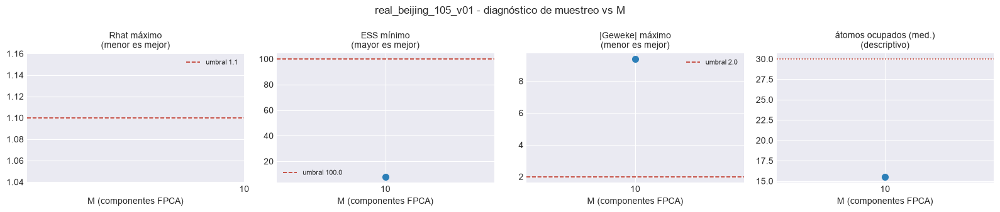

In [13]:
barrido_df = tabla_barrido(EST, M_OK, PATH_BARRIDO)
_fmt = {c: "{:.4f}" for c in ("rhat_max", "geweke_max", "pip_sd_max", "pip_media_activas")
        if c in barrido_df.columns} | {"ess_min": "{:.0f}", "ocupacion_media": "{:.2f}"}
display(barrido_df.style.format(_fmt, na_rep="-")
        .background_gradient(subset=["rhat_max"], cmap="RdYlGn_r", vmin=1.0, vmax=1.2)
        .background_gradient(subset=["ess_min"], cmap="RdYlGn", vmin=0, vmax=500)
        .set_caption("Diagnóstico de muestreo a lo largo del barrido en M"))

plot_diagnostico_vs_M(barrido_df, EST[M_OK[0]]["res_conv"]["umbrales"], EXPERIMENT_BASE,
                      PATH_BARRIDO / "81_diagnostico_vs_M.png")
plt.show()

FPC,1,2,3,4,5,6,7,8,9,10
M,,,,,,,,,,
10,8.76,9.66,20.13,24.34,18.72,9.91,11.42,26.33,11.50,14.61


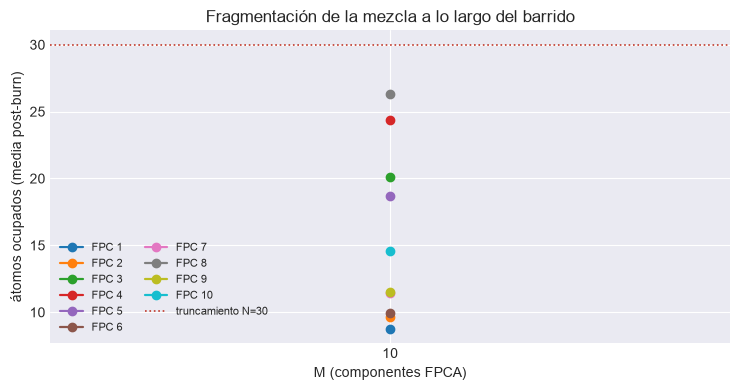

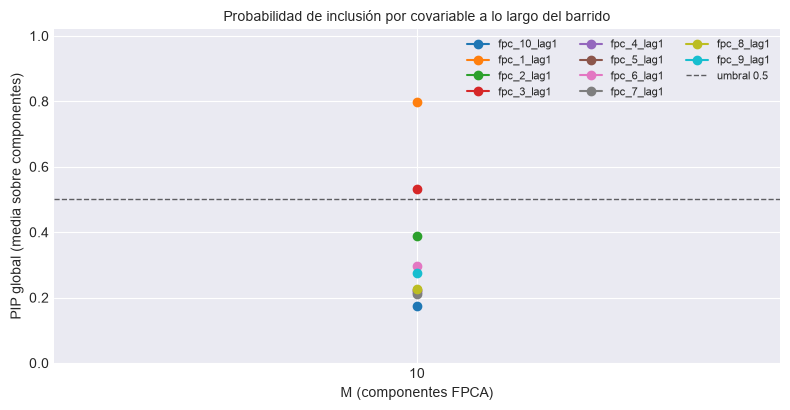

In [14]:
# Ocupación por M y componente: dice si al subir M el modelo parte la mezcla en más átomos.
ocup_todo, piv = ocupacion_barrido(EST, M_OK, PATH_BARRIDO)
display(piv.style.format("{:.2f}", na_rep="-").background_gradient(cmap="RdYlGn_r", axis=None)
        .set_caption("Átomos ocupados (media post-burn) por M y componente FPCA"))
plot_ocupacion_vs_M(piv, int(ocup_todo["N_trunc"].iloc[0]), PATH_BARRIDO / "82_ocupacion_por_M.png")
plt.show()

# PIP por covariable a lo largo del barrido (formato largo).
pip_largo = pip_barrido(EST, M_OK, PATH_BARRIDO)
plot_pip_vs_M(pip_largo, M_OK, PATH_BARRIDO / "83_pip_por_M.png")
plt.show()

In [15]:
veredicto_barrido(barrido_df, EXPERIMENT_BASE, M_FPCA_LIST, M_OK, PATH_BARRIDO)
print("Continuar con 105_04_evaluacion, declarando el mismo M_FPCA_LIST.")

  BARRIDO real_beijing_105_v01   ·   M evaluados: [10]
  M=10  p=10  Rhatmax=nan  ESSmin=8  ocup=15.5/30  X NO CONVERGE
------------------------------------------------------------------
X NO convergen: M = [10]. Excluirlos de la comparacion de _04/_05,
  o subir nsim/burn antes de leer su error como efecto de M.
Tablas y figuras cruzadas en C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_beijing_105_v01_barrido_M  (archivos 80-83)
Continuar con 105_04_evaluacion, declarando el mismo M_FPCA_LIST.
